# InfoArg: estructurar automáticamente artículos de Wikipedia sobre Argentina

**Trabajo Práctico Integrador · Procesamiento de Lenguaje Natural · Universidad de Palermo**

Integrantes: Mirko Doljanica Monge · Jimena Medina · Rashid Zuain

---

**Problema.** En el corpus `corpus-wiki-arg` (1.000 artículos de Wikipedia en español sobre Argentina), uno de cada cuatro artículos no tiene *infobox*: la ficha con los datos clave (fecha y lugar de nacimiento, fundación, país...). Además, el tipo de entidad del artículo (persona, lugar, organización...) no siempre es evidente.

**Objetivo.** Construir un pipeline que, a partir solo del texto del artículo:

1. **clasifique** el tipo de entidad (6 clases), y
2. **extraiga** los datos clave para armar un *borrador de infobox*, que un editor pueda revisar en vez de escribirlo desde cero.

**Estructura del notebook:**

1. Datos y EDA
2. Preprocesamiento
3. Clasificación: comparamos cuatro enfoques vistos en la materia (TF-IDF, n-gramas de caracteres, embeddings de spaCy y un Transformer entrenado desde cero)
4. Extracción de información: reglas vs. NER de spaCy, evaluadas contra los infobox existentes
5. Pipeline completo aplicado a los artículos sin infobox
6. Conclusiones y limitaciones

In [1]:
import json, re, time, random, collections, urllib.request
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED)
Path('resultados').mkdir(exist_ok=True); Path('figuras').mkdir(exist_ok=True)

corpus_path = Path('data/corpus-wiki-arg.jsonl')
if not corpus_path.exists():
    corpus_path.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve('https://github.com/rubin145/curso-nlp/raw/main/data/corpus-wiki-arg.jsonl', corpus_path)
docs = [json.loads(l) for l in open(corpus_path, encoding='utf-8')]

def limpiar_inicio(texto, titulo):
    # Algunos artículos empiezan con restos del pie de imagen ("miniatura|250px|..."): cortamos hasta donde aparece el título
    if re.match(r'\s*(?:miniatura|thumb|imagen|archivo)', texto, re.I):
        clave = re.sub(r'\s*\(.*', '', titulo)[:20]
        i = texto.find(clave, 0, 1500)
        texto = texto[i:] if i > 0 else re.sub(r'^(?:\s*(?:miniatura\w*|thumb)\|[^\n]*?(?:px\||\n))+', '', texto, flags=re.I)
    return texto.strip()
n_limpios = 0
for d in docs:
    t = limpiar_inicio(d['text'], d['title']); n_limpios += t != d['text'].strip(); d['text'] = t
print(len(docs), 'artículos | campos:', list(docs[0].keys()))
print('artículos con restos de imagen al comienzo, limpiados:', n_limpios)

1000 artículos | campos: ['entity_type', 'url', 'title', 'text', 'categories', 'infobox', 'internal_links', 'external_links', 'headings', 'page_id', 'title_key', 'last_edit', 'wikitext']
artículos con restos de imagen al comienzo, limpiados: 94


## 1. Datos y análisis exploratorio

              articulos  con_infobox  palabras_mediana
tipo                                                  
CreativeWork        168         0.70             381.0
Event               166         0.66             945.0
Organization        166         0.79             648.0
Person              173         0.75             603.0
Place               167         0.83             488.0
Thing               160         0.76             252.5

Sin infobox: 252 artículos (25%)


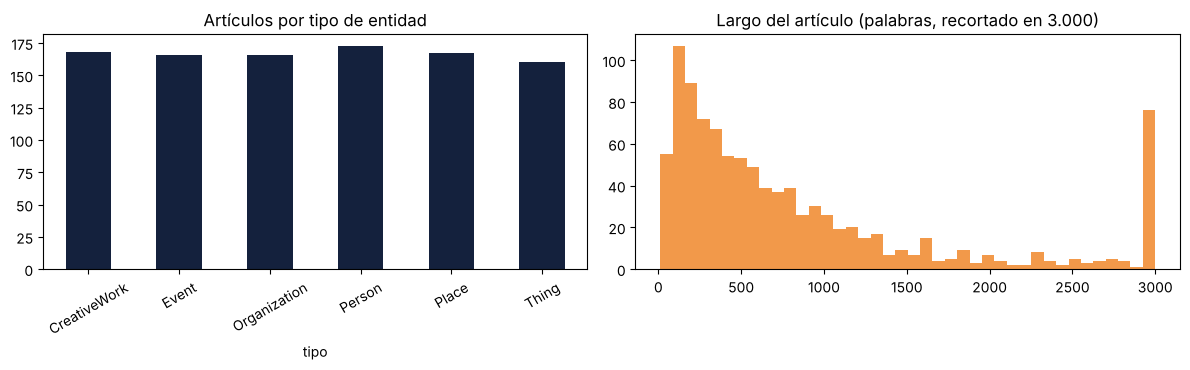

In [2]:
df = pd.DataFrame({
    'titulo': [d['title'] for d in docs],
    'tipo': [d['entity_type'] for d in docs],
    'texto': [d['text'] for d in docs],
    'tiene_infobox': [bool(d.get('infobox')) for d in docs],
    'n_palabras': [len(d['text'].split()) for d in docs],
    'n_categorias': [len(d.get('categories') or []) for d in docs],
})
resumen = df.groupby('tipo').agg(articulos=('titulo', 'size'), con_infobox=('tiene_infobox', 'mean'),
                                 palabras_mediana=('n_palabras', 'median')).round(2)
print(resumen.to_string())
print(f"\nSin infobox: {(~df.tiene_infobox).sum()} artículos ({(~df.tiene_infobox).mean():.0%})")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
resumen.articulos.plot.bar(ax=ax[0], color='#14213D'); ax[0].set_title('Artículos por tipo de entidad'); ax[0].tick_params(axis='x', rotation=30)
ax[1].hist(df.n_palabras.clip(upper=3000), bins=40, color='#F2994A'); ax[1].set_title('Largo del artículo (palabras, recortado en 3.000)')
plt.tight_layout(); plt.savefig('figuras/eda.png', dpi=150); plt.show()

In [3]:
# ¿Qué hay dentro de cada clase? Muestras de títulos y palabras más características (TF-IDF promedio por clase)
for t in sorted(df.tipo.unique()):
    print(f"{t:13s}", ' · '.join(df[df.tipo == t].titulo.sample(6, random_state=SEED)))

CreativeWork  Anexo:Películas argentinas de 1941 · El hogar que nos negamos · De tango y lo demás · La leona (telenovela de 2016) · Shock TV (libro de Oro: Cinefania) · Catálogo Mello Teggia
Event         Fiebre amarilla en Buenos Aires · Terremoto de Salta de 2010 · Noche de los Bastones Largos · Día de la Lealtad · Laudo limítrofe entre Argentina y Chile de 1902 · Copamiento del Batallón de Arsenales 121
Organization  Universidad Nacional de Chilecito · Cámara Federal en lo Penal de la Nación · Telefe Rosario · Escuela Argentina de Fotografía · Escuela Nacional de Bellas Artes Prilidiano Pueyrredón · Buenos Aires Rowing Club
Person        Zulema Daher · Uriel Lozano · Ricardo Allegri · Bárbara Elizabeth Alí · Júlio César (futbolista) · Eleodoro Lobos
Place         Parque nacional Baritú · Museo de Astronomía y Geofísica · Museo de Anatomía Humana Normal · Estación Juan Jufré · Estación Aguada Cecilio · Museo Provincial de Bellas Artes Emilio Pettoruti
Thing         Unicato · Mangocho

**Observaciones del EDA:**

- **Clases balanceadas:** cada tipo tiene entre 160 y 173 artículos, así que *accuracy* y *F1 macro* van a dar parecido.
- **Etiquetas ruidosas:** las etiquetas vienen de un mapeo automático (tipo schema.org), no de una anotación manual. Hay buques (*ARA Charrúa*) etiquetados como `Organization` y cargos (*Director supremo...*) como `Event`.
- **`Thing` es una clase "cajón de sastre":** mezcla especies biológicas, barcos, conceptos y elecciones. Es esperable que sea la más difícil.
- **Largo muy variable:** desde unas pocas decenas de palabras hasta varios miles. Por eso usamos el título más el comienzo del artículo, que es donde Wikipedia define la entidad.

## 2. Preprocesamiento

Al cargar los datos ya quitamos los restos de pies de imagen (`miniatura|250px|...`) que aparecen al comienzo de algunos artículos.

Para clasificar, cada artículo se representa como *título + primeras 300 palabras*, con dos tratamientos según el modelo:

- **Modelos de bolsa de palabras (TF-IDF):** pasamos a minúsculas, quitamos números, URLs y puntuación, y eliminamos *stopwords* de spaCy.
- **Modelos con embeddings o Transformer:** usamos el texto sin quitar stopwords, porque ahí el orden y las palabras funcionales aportan.

Para la evaluación separamos un **test estratificado del 20%**, que no se toca hasta el final. Sobre el 80% restante hacemos validación cruzada de 5 folds.

In [4]:
import spacy
nlp = spacy.load('es_core_news_lg')
STOP = nlp.Defaults.stop_words

def entrada(r, n=300):
    return r.titulo + '. ' + ' '.join(r.texto.split()[:n])
def limpiar(t):
    t = t.lower()
    t = re.sub(r'https?://\S+|\d+', ' ', t)
    t = re.sub(r'[^\wáéíóúüñ ]', ' ', t)
    return ' '.join(w for w in t.split() if w not in STOP and len(w) > 2)

df['entrada'] = df.apply(entrada, axis=1)
df['entrada_limpia'] = df.entrada.map(limpiar)
CLASES = sorted(df.tipo.unique())
y = df.tipo.map(CLASES.index).values
idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=0.2, random_state=SEED, stratify=y)
print('train', len(idx_tr), '| test', len(idx_te))
print('\nEjemplo limpio:', df.entrada_limpia[0][:200])

train 800 | test 200

Ejemplo limpio: socias socias serie televisión argentina comedia dramática producida pol emitida canal abril éxito protagonizada mercedes morán andrea pietra nancy dupláa temáticas serie giran vida personal abogadas 


## 3. Clasificación del tipo de entidad

Comparamos estos enfoques:

| # | Modelo | Representación | Módulo de la materia |
|---|---|---|---|
| 0 | Clase mayoritaria | ninguna | línea de base |
| 1 | Regresión logística | TF-IDF de palabras (1-2 gramas) | Preprocesamiento + clasificación |
| 2 | SVM lineal | TF-IDF de n-gramas de caracteres (2-5) | Clasificación |
| 3 | Regresión logística | Promedio de embeddings de spaCy (300 d) | Embeddings |
| 4 | Transformer *encoder* desde cero | BPE propio + atención | Transformers |

In [5]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
modelos = {
    '1. TF-IDF palabras + LogReg': (make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                                                 LogisticRegression(C=10, max_iter=2000)), 'entrada_limpia'),
    '2. TF-IDF caracteres + SVM': (make_pipeline(TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), min_df=2, sublinear_tf=True),
                                                LinearSVC(C=0.5)), 'entrada_limpia'),
}
resultados, preds_test = {}, {}
resultados['0. Clase mayoritaria'] = {'F1 macro (CV)': f1_score(y[idx_tr], np.full(len(idx_tr), np.bincount(y[idx_tr]).argmax()), average='macro'),
                                      'F1 macro (test)': f1_score(y[idx_te], np.full(len(idx_te), np.bincount(y[idx_tr]).argmax()), average='macro')}
for nombre, (m, col) in modelos.items():
    X = df[col].values
    p_cv = cross_val_predict(m, X[idx_tr], y[idx_tr], cv=cv)
    m.fit(X[idx_tr], y[idx_tr]); p_te = m.predict(X[idx_te]); preds_test[nombre] = p_te
    resultados[nombre] = {'F1 macro (CV)': f1_score(y[idx_tr], p_cv, average='macro'),
                          'F1 macro (test)': f1_score(y[idx_te], p_te, average='macro')}
    print(f"{nombre:32s} CV {resultados[nombre]['F1 macro (CV)']:.3f} | test {resultados[nombre]['F1 macro (test)']:.3f}")
tfidf_modelo = modelos['1. TF-IDF palabras + LogReg'][0]

1. TF-IDF palabras + LogReg      CV 0.805 | test 0.812


2. TF-IDF caracteres + SVM       CV 0.793 | test 0.814


In [6]:
# 3. Embeddings de spaCy: vector promedio del documento (tokens alfabéticos, sin stopwords)
t0 = time.time()
E = np.vstack([doc.vector for doc in nlp.pipe(df.entrada_limpia, batch_size=64, disable=['parser', 'ner', 'lemmatizer'])])
print(f'embeddings: {E.shape} en {time.time()-t0:.0f} s')
from sklearn.preprocessing import StandardScaler
m3 = make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=3000))
p_cv = cross_val_predict(m3, E[idx_tr], y[idx_tr], cv=cv)
m3.fit(E[idx_tr], y[idx_tr]); p_te = m3.predict(E[idx_te])
nombre = '3. Embeddings spaCy + LogReg'; preds_test[nombre] = p_te
resultados[nombre] = {'F1 macro (CV)': f1_score(y[idx_tr], p_cv, average='macro'), 'F1 macro (test)': f1_score(y[idx_te], p_te, average='macro')}
print(nombre, {k: round(v, 3) for k, v in resultados[nombre].items()})

embeddings: (1000, 300) en 5 s


3. Embeddings spaCy + LogReg {'F1 macro (CV)': 0.778, 'F1 macro (test)': 0.806}


### 3.1 Transformer *encoder* entrenado desde cero

Es un modelo chico, adecuado para unos 800 ejemplos de entrenamiento:

- **Tokenizador:** BPE propio de 8.000 tokens, entrenado con la librería `tokenizers` de HuggingFace.
- **Arquitectura:** 2 capas de *self-attention* con 4 cabezas, `d_model` 128 y embeddings posicionales aprendidos.
- **Salida:** *pooling* promedio sobre los tokens válidos y una capa softmax.

Como entrenarlo 5 veces es caro en CPU, lo evaluamos con un único split de validación (15% del train) para el *early stopping* y después en el test.

In [7]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tokenizers import Tokenizer, models as tkm, trainers, pre_tokenizers, normalizers
tf.random.set_seed(SEED)

tok = Tokenizer(tkm.BPE(unk_token='[UNK]')); tok.normalizer = normalizers.Sequence([normalizers.NFC(), normalizers.Lowercase()])
tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=True)
tok.train_from_iterator(df.entrada.values[idx_tr], trainers.BpeTrainer(vocab_size=8000, min_frequency=2, special_tokens=['[PAD]', '[UNK]'],
                        initial_alphabet=pre_tokenizers.ByteLevel.alphabet()))
MAXLEN = 256
def cod(textos):
    X = np.zeros((len(textos), MAXLEN), 'int32')
    for i, t in enumerate(textos):
        ids = tok.encode(t).ids[:MAXLEN]; X[i, :len(ids)] = ids
    return X
XT = cod(df.entrada.values)
sub_tr, sub_va = train_test_split(idx_tr, test_size=0.15, random_state=SEED, stratify=y[idx_tr])

class PosEmb(layers.Layer):
    def __init__(self, v, L, d, **kw):
        super().__init__(**kw); self.t = layers.Embedding(v, d); self.p = layers.Embedding(L, d); self.d = d
    def call(self, x): return self.t(x) * tf.math.sqrt(float(self.d)) + self.p(tf.range(tf.shape(x)[1]))

def encoder_clf(d=128, h=4, ff=256, n=2, drop=0.2):
    inp = keras.Input((MAXLEN,), dtype='int32')
    valid = layers.Lambda(lambda s: tf.not_equal(s, 0))(inp)
    mask = layers.Lambda(lambda m: m[:, tf.newaxis, :])(valid)
    x = layers.Dropout(drop)(PosEmb(tok.get_vocab_size(), MAXLEN, d)(inp))
    for i in range(n):
        a = layers.MultiHeadAttention(h, d // h, dropout=drop)(x, x, attention_mask=mask)
        x = layers.LayerNormalization(epsilon=1e-6)(x + layers.Dropout(drop)(a))
        f = layers.Dense(d)(layers.Dense(ff, activation='gelu')(x))
        x = layers.LayerNormalization(epsilon=1e-6)(x + layers.Dropout(drop)(f))
    m = layers.Lambda(lambda z: tf.cast(z, tf.float32)[..., tf.newaxis])(valid)
    pooled = layers.Lambda(lambda t: tf.reduce_sum(t[0] * t[1], 1) / tf.reduce_sum(t[1], 1))([x, m])
    out = layers.Dense(len(CLASES), activation='softmax')(layers.Dropout(drop)(pooled))
    return keras.Model(inp, out)

enc = encoder_clf()
enc.compile(keras.optimizers.AdamW(5e-4, weight_decay=0.01), 'sparse_categorical_crossentropy', metrics=['accuracy'])
print(f'parámetros: {enc.count_params():,}')
t0 = time.time()
hist = enc.fit(XT[sub_tr], y[sub_tr], validation_data=(XT[sub_va], y[sub_va]), epochs=40, batch_size=32, verbose=0,
               callbacks=[keras.callbacks.EarlyStopping('val_loss', patience=6, restore_best_weights=True)])
p_te = enc.predict(XT[idx_te], verbose=0).argmax(1)
p_va = enc.predict(XT[sub_va], verbose=0).argmax(1)
nombre = '4. Transformer desde cero'; preds_test[nombre] = p_te
resultados[nombre] = {'F1 macro (CV)': f1_score(y[sub_va], p_va, average='macro'), 'F1 macro (test)': f1_score(y[idx_te], p_te, average='macro')}
print(f"{len(hist.history['loss'])} épocas en {time.time()-t0:.0f} s |", {k: round(v, 3) for k, v in resultados[nombre].items()}, '(CV = validación simple)')

parámetros: 1,322,502


8 épocas en 84 s | {'F1 macro (CV)': 0.74, 'F1 macro (test)': 0.687} (CV = validación simple)


In [8]:
tabla_clf = pd.DataFrame(resultados).T.round(3)
tabla_clf['accuracy (test)'] = [accuracy_score(y[idx_te], np.full(len(idx_te), np.bincount(y[idx_tr]).argmax()))] + \
                               [accuracy_score(y[idx_te], preds_test[k]) for k in tabla_clf.index[1:]]
tabla_clf = tabla_clf.round(3); tabla_clf.to_csv('resultados/clasificacion.csv')
print(tabla_clf.to_string())
mejor = tabla_clf.index[1:][tabla_clf['F1 macro (test)'].values[1:].argmax()]
print('\nMejor en test:', mejor)

                              F1 macro (CV)  F1 macro (test)  accuracy (test)
0. Clase mayoritaria                  0.049            0.050            0.175
1. TF-IDF palabras + LogReg           0.805            0.812            0.815
2. TF-IDF caracteres + SVM            0.793            0.814            0.815
3. Embeddings spaCy + LogReg          0.778            0.806            0.810
4. Transformer desde cero             0.740            0.687            0.690

Mejor en test: 2. TF-IDF caracteres + SVM


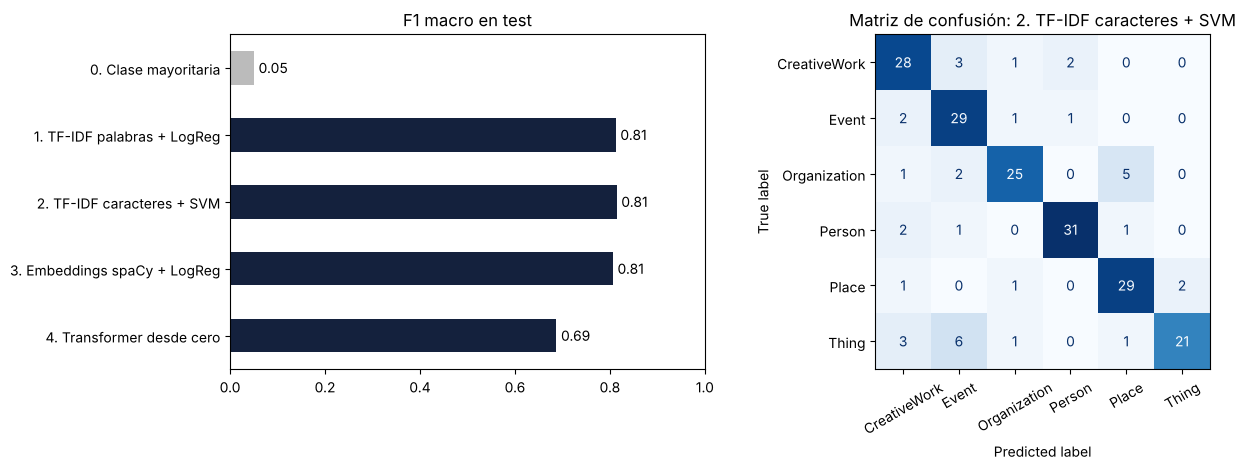

              precision    recall  f1-score   support

CreativeWork      0.757     0.824     0.789        34
       Event      0.707     0.879     0.784        33
Organization      0.862     0.758     0.806        33
      Person      0.912     0.886     0.899        35
       Place      0.806     0.879     0.841        33
       Thing      0.913     0.656     0.764        32

    accuracy                          0.815       200
   macro avg      0.826     0.813     0.814       200
weighted avg      0.826     0.815     0.815       200



In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
tabla_clf['F1 macro (test)'].plot.barh(ax=ax[0], color=['#BBBBBB'] + ['#14213D'] * (len(tabla_clf) - 1))
ax[0].set_xlim(0, 1); ax[0].set_title('F1 macro en test'); ax[0].invert_yaxis()
for i, v in enumerate(tabla_clf['F1 macro (test)']): ax[0].text(v + 0.01, i, f'{v:.2f}', va='center')
ConfusionMatrixDisplay(confusion_matrix(y[idx_te], preds_test[mejor]), display_labels=CLASES).plot(ax=ax[1], cmap='Blues', colorbar=False, xticks_rotation=30)
ax[1].set_title(f'Matriz de confusión: {mejor}')
plt.tight_layout(); plt.savefig('figuras/clasificacion.png', dpi=150); plt.show()
print(classification_report(y[idx_te], preds_test[mejor], target_names=CLASES, digits=3))

### 3.2 Análisis de errores

In [10]:
err = pd.DataFrame({'titulo': df.titulo.values[idx_te], 'real': [CLASES[i] for i in y[idx_te]],
                    'predicho': [CLASES[i] for i in preds_test[mejor]]})
err = err[err.real != err.predicho]
print(f'{len(err)} errores de {len(idx_te)}\n')
print(err.groupby(['real', 'predicho']).size().sort_values(ascending=False).head(8).to_string())
print('\nEjemplos:'); print(err.sample(min(15, len(err)), random_state=SEED).to_string(index=False))

37 errores de 200

real          predicho    
Thing         Event           6
Organization  Place           5
CreativeWork  Event           3
Thing         CreativeWork    3
CreativeWork  Person          2
Organization  Event           2
Event         CreativeWork    2
Person        CreativeWork    2

Ejemplos:
                                           titulo         real     predicho
                     Código Alimentario Argentino CreativeWork Organization
                                  Pampero (globo)        Thing        Event
          Ecorregión terrestre sabana uruguayense        Place        Thing
                                     Uriel Lozano       Person CreativeWork
                              Juana Gabriela Moro       Person        Event
                                         Mangocho        Thing CreativeWork
                         Museo Nacional del Arroz Organization        Place
                            Transporte La Perlita Organization        Place
   

In [11]:
# ¿Qué palabras usa el modelo lineal para decidir? (coeficientes más altos por clase)
vec, clf = tfidf_modelo.named_steps['tfidfvectorizer'], tfidf_modelo.named_steps['logisticregression']
voc = np.array(vec.get_feature_names_out())
for i, c in enumerate(CLASES):
    print(f"{c:13s}", ', '.join(voc[np.argsort(clf.coef_[i])[-10:][::-1]]))

CreativeWork  libro, novela, protagonizada, telenovela, argumento, amor, editorial, serie, personajes, publicada
Event         gobierno, fuerzas, batalla, provincias, premios, torneo, center, octubre, córdoba, cumbre
Organization  empresa, fundada, banco, sede, grupo, edificio, empresas, decreto, creado, historia
Person        biografía, nació, carrera, universidad, trayectoria, trabajó, argentino, aires, fundó, josé
Place         estación, departamento, museo, parque, inaugurado, san, ubicado, nombre, ferrocarril, ubicada
Thing         especie, género, the, familia, brasil, categoría, sur, categoría flora, fósiles, américa sur


## 4. Extracción de información para el borrador de infobox

Nos enfocamos en los campos de mayor valor y que tienen *gold standard* en los infobox existentes:

| Tipo | Campos | Infobox con el dato |
|---|---|---|
| `Person` | fecha y lugar de nacimiento, fecha y lugar de fallecimiento, ocupación | ~100 |
| `Organization` | año de fundación | ~70 |

Comparamos dos extractores:

- **A. Reglas:** aprovechan una convención de estilo de Wikipedia: *"Nombre (Lugar, 3 de mayo de 1950 - Lugar, 4 de junio de 2010) fue un X argentino..."*.
- **B. NER de spaCy:** toma la primera entidad `LOC` y las fechas de la primera oración, sin depender del paréntesis.

**Evaluación contra los infobox existentes:**

- **Fechas:** acierto en el año y, cuando el infobox lo tiene, en la fecha completa.
- **Lugares:** acierto si el lugar extraído coincide con la primera localidad del infobox (comparación normalizada).
- **Ocupación:** solapamiento de palabras (ROUGE-1).

In [12]:
MESES = 'enero febrero marzo abril mayo junio julio agosto septiembre octubre noviembre diciembre'.split()
FECHA_RE = re.compile(r'(?:(\d{1,2})\s+de\s+(' + '|'.join(MESES + ['setiembre']) + r')\s+de\s+)?(\d{3,4})', re.I)

def limpiar_wiki(v):
    v = str(v or '')
    v = re.sub(r'\{\{(?:bandera|band|flagicon)\|[^|\[}]*', ' ', v, flags=re.I)        # {{bandera|ARG -> ''
    v = re.sub(r'\{\{[A-Z]{3}\}?\}?', ' ', v)                                             # {{ARG -> ''
    v = re.sub(r'\{\{fecha(?: de muerte| de nacimiento)?\|(\d+)\|(\d+)\|(\d+)[^}]*\}?\}?', lambda m: f"{m.group(1)} de {MESES[int(m.group(2))-1] if 0 < int(m.group(2)) <= 12 else ''} de {m.group(3)}", v, flags=re.I)
    v = re.sub(r'\[\[(?:[^\]|]*\|)?([^\]]*)\]\]', r'\1', v)
    v = re.sub(r'\{\{[^{}|]*\|?|\}\}|<[^>]+>|\'\'+', ' ', v)
    return re.sub(r'\s+', ' ', v).strip(' ,;')

def norm_fecha(s):
    m = FECHA_RE.search(s or '')
    if not m: return None
    d, mes, a = m.groups()
    mes = 'septiembre' if (mes or '').lower() == 'setiembre' else (mes or '').lower()
    return {'año': a, 'completa': f'{int(d)} {mes} {a}' if d else None}

import unicodedata
def norm_lugar(s):
    s = unicodedata.normalize('NFKD', limpiar_wiki(s).lower()).encode('ascii', 'ignore').decode()
    s = re.split(r'[,(]', s)[0]
    return re.sub(r'[^a-z ]', '', s).strip()

def gold_persona(ib):
    return {'nac_fecha': norm_fecha(limpiar_wiki(ib.get('fecha de nacimiento'))), 'nac_lugar': norm_lugar(ib.get('lugar de nacimiento')),
            'fall_fecha': norm_fecha(limpiar_wiki(ib.get('fecha de fallecimiento'))), 'fall_lugar': norm_lugar(ib.get('lugar de fallecimiento')),
            'ocupacion': limpiar_wiki(ib.get('ocupación')).lower()}

# --- Extractor A: reglas sobre el paréntesis inicial y la definición "fue/es un(a) ..." ---
PAREN = re.compile(r'^[^(]{0,120}\(([^)]{3,200})\)')
OCUP = re.compile(r'\)\s*(?:,\s*[^,]{0,40},\s*)?(?:fue|es|era)\s+(?:un|una)\s+(.{3,120}?)\s+(?:argentin[oa]s?|nacionalizad[oa]|de nacionalidad|que|nacid[oa]|conocid[oa]|,|\.)', re.I)
def extraer_reglas(texto):
    out = {'nac_fecha': None, 'nac_lugar': '', 'fall_fecha': None, 'fall_lugar': '', 'ocupacion': ''}
    texto = re.sub(r'^(?:miniatura|thumb)[^\n]*\n', '', texto.lstrip())   # restos de pies de imagen
    m = PAREN.search(texto)
    if m:
        # separador nacimiento / fallecimiento: guion o raya (con o sin espacios) después de un dígito, '?' o espacio
        partes = re.split(r'(?<=[\d?\s])[-–—]\s*', m.group(1).replace(';', ','))
        for clave, parte in zip(['nac', 'fall'], partes[:2]):
            f = norm_fecha(parte)
            out[f'{clave}_fecha'] = f
            lugar = FECHA_RE.split(parte)[0] if f else parte
            lugar = re.sub(r'^\s*(?:n\.|f\.|m\.|†|\*)\s*|\b(?:el|en|circa|c\.|ca\.)\s', ' ', lugar)
            out[f'{clave}_lugar'] = norm_lugar(lugar)
        if out['fall_lugar'] in ('ibidem', 'idem', 'id', 'misma ciudad'):
            out['fall_lugar'] = out['nac_lugar']
    o = OCUP.search(texto[:600])
    if o: out['ocupacion'] = o.group(1).lower()
    return out

# --- Extractor B: NER de spaCy sobre la primera oración ---
def extraer_ner(doc):
    out = {'nac_fecha': None, 'nac_lugar': '', 'fall_fecha': None, 'fall_lugar': '', 'ocupacion': ''}
    sent = next(doc.sents).text
    fechas = [norm_fecha(m.group(0)) for m in FECHA_RE.finditer(sent)]
    if fechas: out['nac_fecha'] = fechas[0]
    if len(fechas) > 1: out['fall_fecha'] = fechas[1]
    locs = [e.text for e in next(doc.sents).ents if e.label_ == 'LOC']
    if locs: out['nac_lugar'] = norm_lugar(locs[0])
    if len(locs) > 1: out['fall_lugar'] = norm_lugar(locs[1])
    return out

r = docs[[d['title'] for d in docs].index('Samuel Eichelbaum')]
print(r['text'][:180]); print('A reglas:', extraer_reglas(r['text'])); print('Gold   :', gold_persona(r['infobox']))

Samuel Eichelbaum (Villa Domínguez, Entre Ríos, 14 de noviembre de 1894 - Buenos Aires, 4 de mayo de 1967) fue un escritor, periodista, dramaturgo, crítico y traductor argentino.


A reglas: {'nac_fecha': {'año': '1894', 'completa': '14 noviembre 1894'}, 'nac_lugar': 'villa dominguez', 'fall_fecha': {'año': '1967', 'completa': '4 mayo 1967'}, 'fall_lugar': 'buenos aires', 'ocupacion': 'escritor, periodista, dramaturgo, crítico y traductor'}
Gold   : {'nac_fecha': {'año': '1894', 'completa': '14 noviembre 1894'}, 'nac_lugar': 'villa dominguez', 'fall_fecha': {'año': '1967', 'completa': '4 mayo 1967'}, 'fall_lugar': 'buenos aires', 'ocupacion': ''}


In [13]:
personas = [d for d in docs if d['entity_type'] == 'Person' and d.get('infobox')]
filas = []
docs_sp = list(nlp.pipe([' '.join(d['text'].split()[:120]) for d in personas], batch_size=32))
for d, dsp in zip(personas, docs_sp):
    g = gold_persona(d['infobox']); A = extraer_reglas(d['text']); B = extraer_ner(dsp)
    C = {k: (A[k] or B[k]) for k in A}  # combinado: reglas y, si no encuentran, NER
    for metodo, P in [('A. Reglas', A), ('B. NER spaCy', B), ('C. Reglas + NER', C)]:
        for campo in ['nac_fecha', 'fall_fecha']:
            if g[campo]:
                filas.append({'metodo': metodo, 'campo': campo + ' (año)', 'acierto': bool(P[campo]) and P[campo]['año'] == g[campo]['año'], 'cubierto': bool(P[campo])})
                if g[campo]['completa']:
                    filas.append({'metodo': metodo, 'campo': campo + ' (completa)', 'acierto': bool(P[campo]) and P[campo]['completa'] == g[campo]['completa'], 'cubierto': bool(P[campo])})
        for campo in ['nac_lugar', 'fall_lugar']:
            if g[campo]:
                ok = bool(P[campo]) and (P[campo] == g[campo] or P[campo].endswith(g[campo]) or g[campo].endswith(P[campo]))
                filas.append({'metodo': metodo, 'campo': campo, 'acierto': ok, 'cubierto': bool(P[campo])})
        if g['ocupacion'] and metodo != 'B. NER spaCy':
            gw, pw = set(re.findall(r'\w+', g['ocupacion'])) - STOP, set(re.findall(r'\w+', P['ocupacion'])) - STOP
            filas.append({'metodo': metodo, 'campo': 'ocupacion (ROUGE-1)', 'acierto': 0 if not pw else 2 * len(gw & pw) / (len(gw) + len(pw)), 'cubierto': bool(pw)})
ev = pd.DataFrame(filas)
tabla_ext = ev.pivot_table(index='campo', columns='metodo', values='acierto', aggfunc='mean').round(3)
tabla_ext['n (gold)'] = ev[ev.metodo == 'A. Reglas'].groupby('campo').size()
tabla_ext.to_csv('resultados/extraccion_personas.csv')
print(f'{len(personas)} personas con infobox\n'); print(tabla_ext.to_string())

130 personas con infobox

metodo                A. Reglas B. NER spaCy C. Reglas + NER  n (gold)
campo                                                                 
fall_fecha (año)       0.857143     0.816327        0.897959        49
fall_fecha (completa)  0.714286     0.690476        0.738095        42
fall_lugar                 0.64         0.36            0.66        50
nac_fecha (año)         0.90625     0.916667          0.9375        96
nac_fecha (completa)   0.876712     0.863014        0.876712        73
nac_lugar              0.757895     0.673684             0.8        95
ocupacion (ROUGE-1)    0.531857          NaN        0.531857        55


In [14]:
# Organizaciones: año de fundación (primer año "fundada/creada/inaugurada en ..." o, si no, el primer año del texto)
FUND = re.compile(r'(?:fundad[oa]s?|cread[oa]s?|establecid[oa]s?|inaugurad[oa]s?|nació|surgió|fundó|creó)[^.]{0,60}?(\b1[5-9]\d\d\b|\b20[0-2]\d\b)', re.I)
ANIO = re.compile(r'\b(1[5-9]\d\d|20[0-2]\d)\b')
orgs = [d for d in docs if d['entity_type'] == 'Organization' and d.get('infobox') and ANIO.search(limpiar_wiki(d['infobox'].get('fundación')))]
fil = []
for d in orgs:
    gold = ANIO.search(limpiar_wiki(d['infobox']['fundación'])).group(1)
    t = ' '.join(d['text'].split()[:400])
    a = FUND.search(t); b = ANIO.search(t)
    fil.append({'A. Patrón "fundada en"': (a.group(1) if a else None) == gold, 'B. Primer año del texto': (b.group(1) if b else None) == gold,
                'C. Patrón o primer año': ((a.group(1) if a else (b.group(1) if b else None)) == gold)})
tabla_org = pd.DataFrame(fil).mean().round(3).to_frame(f'acierto año de fundación (n={len(orgs)})')
print(tabla_org.to_string())

                         acierto año de fundación (n=61)
A. Patrón "fundada en"                             0.443
B. Primer año del texto                            0.590
C. Patrón o primer año                             0.623


## 5. Pipeline completo: borradores de infobox para artículos que no tienen

El pipeline completo es: **texto → clasificador → extractor del tipo correspondiente → borrador**.

Lo aplicamos a los artículos del corpus **sin infobox**. Así se ve el uso real: un editor recibe una ficha prellenada para revisar.

In [15]:
clf_final = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), LogisticRegression(C=10, max_iter=2000))
con_ib = df.index[df.tiene_infobox]
clf_final.fit(df.entrada_limpia[con_ib], y[con_ib])   # entrenado solo con artículos que sí tienen infobox
sin_ib = df[~df.tiene_infobox].copy()
anexos = sin_ib.titulo.str.startswith('Anexo:')
print(f'{anexos.sum()} de los {len(sin_ib)} artículos sin infobox son anexos (listas), que no llevan infobox: los excluimos')
sin_ib = sin_ib[~anexos]
proba = clf_final.predict_proba(sin_ib.entrada_limpia)
sin_ib['tipo_predicho'] = [CLASES[i] for i in proba.argmax(1)]; sin_ib['confianza'] = proba.max(1)

def borrador(r):
    b = {'nombre': r.titulo, 'tipo (predicho)': f"{r.tipo_predicho} ({r.confianza:.0%})" + ('' if r.confianza >= 0.4 else ' · REVISAR')}
    if r.tipo_predicho == 'Person':
        e = extraer_reglas(r.texto)
        if not e['nac_fecha'] and not e['nac_lugar']:
            e2 = extraer_ner(nlp(' '.join(r.texto.split()[:120]))); e = {k: e[k] or e2[k] for k in e}
        for k, et in [('nac_lugar', 'lugar de nacimiento'), ('nac_fecha', 'fecha de nacimiento'), ('fall_lugar', 'lugar de fallecimiento'), ('fall_fecha', 'fecha de fallecimiento'), ('ocupacion', 'ocupación')]:
            v = e[k]
            if isinstance(v, dict): v = v['completa'] or v['año']
            if v: b[et] = v
    elif r.tipo_predicho == 'Organization':
        t = ' '.join(r.texto.split()[:400]); a = FUND.search(t) or ANIO.search(t)
        if a: b['fundación'] = a.group(1)
    return b

sin_ib['borrador'] = sin_ib.apply(borrador, axis=1)
print(f"{len(sin_ib)} artículos sin infobox (sin anexos) | acuerdo del tipo predicho con la etiqueta del corpus: {(sin_ib.tipo_predicho == sin_ib.tipo).mean():.1%}")
print(sin_ib.tipo_predicho.value_counts().to_string())
sin_ib[['titulo', 'tipo', 'tipo_predicho', 'confianza']].assign(borrador=sin_ib.borrador.map(lambda b: json.dumps(b, ensure_ascii=False))).to_csv('resultados/borradores_infobox.csv', index=False)
for _, r in sin_ib[sin_ib.tipo_predicho.isin(['Person', 'Organization'])].sample(5, random_state=1).iterrows():
    print('\n' + '─' * 90); print(r.texto[:220].replace('\n', ' '), '...')
    for k, v in r.borrador.items(): print(f'   {k:24s} {v}')

44 de los 252 artículos sin infobox son anexos (listas), que no llevan infobox: los excluimos
208 artículos sin infobox (sin anexos) | acuerdo del tipo predicho con la etiqueta del corpus: 68.8%
tipo_predicho
Event           49
Organization    41
Person          41
Place           31
CreativeWork    30
Thing           16

──────────────────────────────────────────────────────────────────────────────────────────
El Instituto Universitario Nacional de Derechos Humanos Madres de Plaza de Mayo  (antiguamente Universidad Popular de las Madres de Plaza de Mayo) es una institución de educación superior pública universitaria argentina  ...
   nombre                   Instituto Universitario de Madres de Plaza de Mayo
   tipo (predicho)          Organization (74%)
   fundación                2000

──────────────────────────────────────────────────────────────────────────────────────────
Biblioteca Carlos H. Barderi se encuentra en el Instituto de Genética Ewald A. Favret perteneciente al Centro

## 6. Conclusiones, limitaciones y trabajo futuro

**Clasificación del tipo de entidad:**

- **Los tres enfoques clásicos empatan:** TF-IDF de palabras, TF-IDF de caracteres y embeddings de spaCy quedan todos en **F1 macro ≈ 0,81** en test, muy lejos de la línea de base (0,05). Las diferencias entre ellos (≤ 0,01) son menores que la variación entre folds. De hecho, en validación cruzada gana TF-IDF de palabras y en test, el de caracteres.
- **El Transformer queda abajo:** entrenado desde cero, se ubica entre 0,69 y 0,74 según la corrida. Con 800 ejemplos no alcanza a aprender representaciones mejores que las que TF-IDF obtiene "gratis", y además es inestable.
- **TF-IDF + regresión logística es la mejor opción práctica:** rinde igual que el mejor modelo, entrena en segundos y es interpretable. Sus palabras clave por clase tienen sentido: *nació, biografía* para personas; *estación, museo* para lugares; *especie, género* para `Thing`.
- **Errores:** la mayoría se concentra en `Thing` y en el límite `Organization`/`Place` (museos, centros culturales). Muchos son ambigüedades reales o ruido de etiqueta: un globo aerostático etiquetado como `Thing`, un código legal como `CreativeWork`.

**Extracción de datos de personas** (acierto contra los infobox existentes):

| Campo | Acierto (reglas + NER) |
|---|---|
| Año de nacimiento | 94% |
| Fecha de nacimiento completa | 88% |
| Lugar de nacimiento | 80% |
| Año de fallecimiento | 90% |

- **Reglas vs. NER:** las reglas, que aprovechan la convención de Wikipedia *"Nombre (Lugar, fecha – Lugar, fecha)"*, superan al NER genérico de spaCy en lugares. El NER aporta cobertura cuando no hay paréntesis, y **combinarlos es lo mejor en todos los campos**.
- **Ocupación:** queda más baja (ROUGE-1 0,53) porque el infobox suele resumirla distinto que el texto.

**Organizaciones:** el año de fundación se acierta en el 62% de los casos. Es más difícil porque el primer año del texto no siempre es la fundación.

**Uso práctico:** de los 208 artículos sin infobox (sin contar anexos), el pipeline genera un borrador para cada uno en segundos.

- **Avisos de revisión:** marca para revisar los casos de baja confianza del clasificador.
- **Desempeño más bajo que en test:** el clasificador coincide con la etiqueta del corpus en ~69% de estos artículos, contra ~81% en el test. Son artículos más cortos o atípicos, lo que muestra que el editor humano sigue siendo necesario.

**Limitaciones:**

- **Etiquetas automáticas:** las etiquetas de tipo son ruidosas, y `Thing` es heterogénea.
- **Gold imperfecto:** son los propios infobox, con formatos mixtos (plantillas, enlaces).
- **Pocos campos:** solo extraemos campos de personas y organizaciones.
- **Texto incompleto:** algunos textos perdieron fechas al eliminar plantillas ("nacido el  en...").
- **Corpus chico:** 1.000 artículos.

**Trabajo futuro:**

- *Fine-tuning* de un modelo pre-entrenado en español (BETO, mT5) para clasificar y para generar el infobox completo.
- Extracción de más campos (sede, fundador, población).
- Una interfaz donde el editor acepte o corrija cada campo propuesto.

In [16]:
print('Clasificación (F1 macro en test):'); print(tabla_clf['F1 macro (test)'].to_string())
print('\nExtracción, personas (acierto):'); print(tabla_ext.to_string())
print('\nExtracción, organizaciones:'); print(tabla_org.to_string())

Clasificación (F1 macro en test):
0. Clase mayoritaria            0.050
1. TF-IDF palabras + LogReg     0.812
2. TF-IDF caracteres + SVM      0.814
3. Embeddings spaCy + LogReg    0.806
4. Transformer desde cero       0.687

Extracción, personas (acierto):
metodo                A. Reglas B. NER spaCy C. Reglas + NER  n (gold)
campo                                                                 
fall_fecha (año)       0.857143     0.816327        0.897959        49
fall_fecha (completa)  0.714286     0.690476        0.738095        42
fall_lugar                 0.64         0.36            0.66        50
nac_fecha (año)         0.90625     0.916667          0.9375        96
nac_fecha (completa)   0.876712     0.863014        0.876712        73
nac_lugar              0.757895     0.673684             0.8        95
ocupacion (ROUGE-1)    0.531857          NaN        0.531857        55

Extracción, organizaciones:
                         acierto año de fundación (n=61)
A. Patrón "fundada